In [1]:
using DifferentialEquations
using Plots
using DelimitedFiles
using DataFrames
using CSV
using LaTeXStrings

In [2]:
# -------------------------
# grid radial
# -------------------------

Nr = 2001
R  = 100.0

dr = R/(Nr-1)

r = collect(0:dr:R)

# -------------------------
# parâmetros
# -------------------------
s=0.5

g3 = 2.0
g2 = -3.0*coth(2.0*s)

# -------------------------
# operadores 4ª ordem
# -------------------------

function d2_4(ϕ,i,dr)

    (-ϕ[i+2] + 16ϕ[i+1] - 30ϕ[i] + 16ϕ[i-1] - ϕ[i-2])/(12dr^2)

end

function d1_4(ϕ,i,dr)

    (-ϕ[i+2] + 8ϕ[i+1] - 8ϕ[i-1] + ϕ[i-2])/(12dr)

end

d1_4 (generic function with 1 method)

In [3]:
# -------------------------
# equações
# -------------------------

function radial_D2!(du, u, p, t)

    Nr, dr, r, g2, g3 = p

    ϕ = @view u[1:Nr]
    π = @view u[Nr+1:2Nr]

    dϕ = @view du[1:Nr]
    dπ = @view du[Nr+1:2Nr]

    # φ_t = π
    dϕ .= π


    # ============================================================
    # r = 0
    #
    # Em 2D:
    #   ∇²φ(0) = 2 φ_rr(0)
    #
    # φ_rr(0) ≈ 2(φ[2]-φ[1])/dr²
    # ============================================================

    lap = 4*(ϕ[2] - ϕ[1])/dr^2

    dπ[1] = lap -
            ϕ[1]*(1 + g2*ϕ[1] + g3*ϕ[1]^2)


    # ============================================================
    # i = 2: segunda ordem
    # ============================================================

    i = 2

    φrr = (ϕ[i+1] - 2ϕ[i] + ϕ[i-1])/dr^2
    φr  = (ϕ[i+1] - ϕ[i-1])/(2dr)

    dπ[i] = φrr + φr/r[i] -
            ϕ[i]*(1 + g2*ϕ[i] + g3*ϕ[i]^2)


    # ============================================================
    # Interior: quarta ordem
    # ============================================================

    for i in 3:Nr-2

        φrr = d2_4(ϕ, i, dr)
        φr  = d1_4(ϕ, i, dr)

        dπ[i] = φrr + φr/r[i] -
                ϕ[i]*(1 + g2*ϕ[i] + g3*ϕ[i]^2)

    end


    # ============================================================
    # i = Nr-1: segunda ordem
    # ============================================================

    i = Nr-1

    φrr = (ϕ[i+1] - 2ϕ[i] + ϕ[i-1])/dr^2
    φr  = (ϕ[i+1] - ϕ[i-1])/(2dr)

    dπ[i] = φrr + φr/r[i] -
            ϕ[i]*(1 + g2*ϕ[i] + g3*ϕ[i]^2)


    # ============================================================
    # r = R: Dirichlet
    # ============================================================

    dϕ[Nr] = 0.0
    dπ[Nr] = 0.0

    return nothing
end

function radial_D3!(du, u, p, t)

    Nr, dr, r, g2, g3 = p

    ϕ = @view u[1:Nr]
    π = @view u[Nr+1:2Nr]

    dϕ = @view du[1:Nr]
    dπ = @view du[Nr+1:2Nr]

    # φ_t = π
    dϕ .= π


    # ============================================================
    # r = 0
    #
    # Em 3D:
    #   ∇²φ(0) = 3 φ_rr(0)
    #
    # φ_rr(0) ≈ 2(φ[2]-φ[1])/dr²
    # ============================================================

    lap = 6*(ϕ[2] - ϕ[1])/dr^2

    dπ[1] = lap -
            ϕ[1]*(1 + g2*ϕ[1] + g3*ϕ[1]^2)


    # ============================================================
    # i = 2: segunda ordem
    # ============================================================

    i = 2

    φrr = (ϕ[i+1] - 2ϕ[i] + ϕ[i-1])/dr^2
    φr  = (ϕ[i+1] - ϕ[i-1])/(2dr)

    dπ[i] = φrr + 2*φr/r[i] -
            ϕ[i]*(1 + g2*ϕ[i] + g3*ϕ[i]^2)


    # ============================================================
    # Interior: quarta ordem
    # ============================================================

    for i in 3:Nr-2

        φrr = d2_4(ϕ, i, dr)
        φr  = d1_4(ϕ, i, dr)

        dπ[i] = φrr + 2* φr/r[i] -
                ϕ[i]*(1 + g2*ϕ[i] + g3*ϕ[i]^2)

    end


    # ============================================================
    # i = Nr-1: segunda ordem
    # ============================================================

    i = Nr-1

    φrr = (ϕ[i+1] - 2ϕ[i] + ϕ[i-1])/dr^2
    φr  = (ϕ[i+1] - ϕ[i-1])/(2dr)

    dπ[i] = φrr + 2*φr/r[i] -
            ϕ[i]*(1 + g2*ϕ[i] + g3*ϕ[i]^2)


    # ============================================================
    # r = R: Dirichlet
    # ============================================================

    dϕ[Nr] = 0.0
    dπ[Nr] = 0.0

    return nothing
end

radial_D3! (generic function with 1 method)

In [16]:
# -------------------------
# condição inicial 2D
# -------------------------
tmp=readdlm("phi_d2_s0.500000.dat")
df=CSV.read("eigfun_l0_d2_s0.500000_mode1.csv", DataFrame)

α=0.35

ϕ0 = zeros(Nr)
ϕ0[1:261]=tmp[1:500:261*500,2]
π0 = zeros(Nr)
π0[1:260]=-α*df.psi[1:5:260*5]

u0 = vcat(ϕ0,π0);

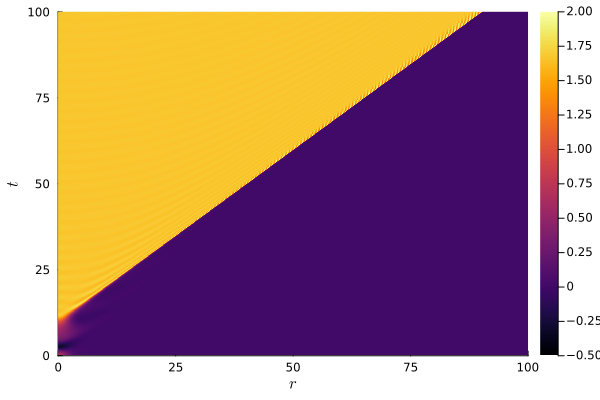

In [17]:
# -------------------------
# solução 2D
# -------------------------
tspan = (0.0,100.0)

prob = ODEProblem(radial_D2!,u0,tspan,(Nr,dr,r,g2,g3))

sol = solve(prob,Tsit5(),saveat=0.1);

nt = length(sol.t)
phi_rt = zeros(nt, Nr)
for k in 1:nt
    phi_rt[k,:] = sol[k][1:Nr]
end

heatmap(r, sol.t, phi_rt, clims=(-0.5,2), xlabel=L"$r$", ylabel=L"$t$")

In [18]:
# -------------------------
# condição inicial 3D
# -------------------------
tmp=readdlm("phi_d3_s0.500000.dat")
df=CSV.read("eigfun_l0_d3_s0.500000_mode1.csv", DataFrame)

α=0.3

ϕ0 = zeros(Nr)
ϕ0[1:261]=tmp[1:500:261*500,2]
π0 = zeros(Nr)
π0[1:260]=-α*df.psi[1:5:260*5]

u0 = vcat(ϕ0,π0);

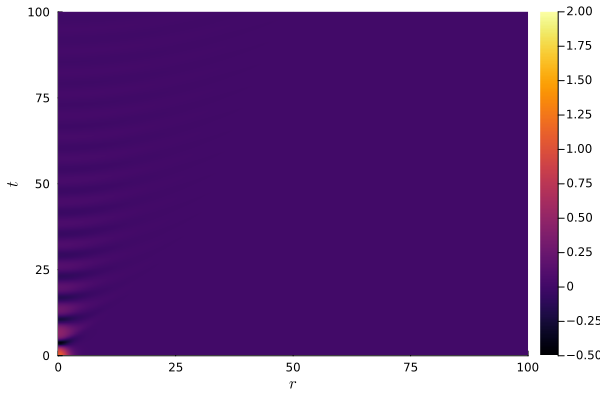

In [19]:
# -------------------------
# solução 3D
# -------------------------
prob = ODEProblem(radial_D3!,u0,tspan,(Nr,dr,r,g2,g3))

sol = solve(prob,Tsit5(),saveat=0.1, adaptive=false, dt = 0.01);

nt = length(sol.t)
phi_rt = zeros(nt, Nr)
for k in 1:nt
    phi_rt[k,:] = sol[k][1:Nr]
end

heatmap(r, sol.t, phi_rt, clims=(-0.5,2), xlabel=L"$r$", ylabel=L"$t$")